# Final Pipeline — 흉부 X-ray 폐렴 분류 (DACON)

**최종 모델**: ImageNet 사전학습 ResNet18, 224×224, **전체 미세조정**(lr 1e-4, Adam, 5 epochs) = 실험 E1b
**리더보드**: 0.9407 (Baseline 0.7468 대비 +19.4%p)

| 단계 | 내용 |
|---|---|
| 1 | Seed 고정 (재현성) |
| 2 | 데이터 준비 · 층화 분할 8:2 |
| 3 | 전처리 · Dataset |
| 4 | 모델 (ResNet18, 전체 층 학습) |
| 5 | 학습 · 최고 검증 AUC 에폭 선택 |
| 6 | 검증 평가 (Acc · AUC · Sens · Spec · 혼동행렬) |
| 7 | 테스트 예측 · 제출 파일 |
| 8 | Grad-CAM |
| 9 | 결과 데이터 (확률 · 판정 · Risk Level) |

**실행 방법**: Colab (T4 GPU) → 런타임 → **모두 실행**
**데이터**: 구글 드라이브 `MyDrive/dacon_chest_xray/data/open.zip` (대회 제공 데이터만 사용)

In [1]:
# 1. Setup & reproducibility


import os, random, copy, time
import numpy as np
import pandas as pd
import torch

SEED = 42

def seed_everything(seed):
    # Fix every source of randomness (python, numpy, torch CPU/GPU, cuDNN)
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    # Fix randomness inside each DataLoader worker
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")


# → 모든 무작위 요소를 SEED=42로 고정해 누가 실행해도 같은 결과가 나오게 하겠다

device: cuda | Tesla T4


In [2]:
# 2. Data & stratified split


from google.colab import drive
from sklearn.model_selection import train_test_split

drive.mount("/content/drive")
PROJECT_DIR = "/content/drive/MyDrive/dacon_chest_xray"
DATA_DIR = "/content/data"
OUT_DIR = os.path.join(PROJECT_DIR, "final")
os.makedirs(OUT_DIR, exist_ok=True)

if not os.path.exists(os.path.join(DATA_DIR, "train")):
    !unzip -q -o "{os.path.join(PROJECT_DIR, 'data', 'open.zip')}" -d "{DATA_DIR}"

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
TRAIN_IMG_DIR = os.path.join(DATA_DIR, "train")
TEST_IMG_DIR = os.path.join(DATA_DIR, "test")

# Stratified 8:2 split (train files are sorted by class → shuffle + keep class ratio)
tr_df, val_df = train_test_split(train_df, test_size=0.2, stratify=train_df["label"], random_state=SEED)

# Same split as all experiments? (split saved in 02_Baseline)
saved = os.path.join(PROJECT_DIR, "data", "split_valid.csv")
if os.path.exists(saved):
    same = sorted(pd.read_csv(saved)["file_name"]) == sorted(val_df["file_name"])
    print("same split as experiments:", same)
# Use the saved order if it exists (identical files, identical order → identical training)
if os.path.exists(saved):
    tr_df = pd.read_csv(os.path.join(PROJECT_DIR, "data", "split_train.csv"))
    val_df = pd.read_csv(saved)

print(f"train {len(tr_df)} | valid {len(val_df)} | test {len(test_df)}")
print("class ratio (normal, pneumonia):", tr_df["label"].value_counts(normalize=True).sort_index().round(3).tolist())


# → 대회 데이터를 풀고, 클래스 비율을 유지한 8:2 층화 분할을 만들어 실험 때와 같은 분할인지 확인하겠다

Mounted at /content/drive
same split as experiments: True
train 4172 | valid 1044 | test 624
class ratio (normal, pneumonia): [0.257, 0.743]


In [3]:
# 3. Transforms & Dataset


from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# No crop / no augmentation (Crop experiments E2 · E2b lowered the leaderboard)
tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),   # 1ch → 3ch for ImageNet weights
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class XrayDataset(Dataset):
    def __init__(self, df, root, has_label=True):
        self.files = df["file_name"].tolist()
        self.labels = df["label"].astype(int).tolist() if has_label else None
        self.root, self.has_label = root, has_label
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        x = tf(Image.open(os.path.join(self.root, self.files[i])).convert("L"))
        return (x, self.labels[i]) if self.has_label else x

def make_loaders():
    g = torch.Generator().manual_seed(SEED)
    kw = dict(num_workers=2, worker_init_fn=seed_worker)
    train_loader = DataLoader(XrayDataset(tr_df, TRAIN_IMG_DIR), batch_size=32, shuffle=True, generator=g, **kw)
    val_loader = DataLoader(XrayDataset(val_df, TRAIN_IMG_DIR), batch_size=64, shuffle=False, **kw)
    test_loader = DataLoader(XrayDataset(test_df, TEST_IMG_DIR, has_label=False), batch_size=64, shuffle=False, **kw)
    return train_loader, val_loader, test_loader


# → 224×224 · 3채널 · ImageNet 정규화 전처리로 학습/검증/테스트 DataLoader를 만들겠다

In [4]:
# 4. Model : ResNet18 full fine-tuning


import torch.nn as nn
from torchvision import models

def build_model():
    # ImageNet pre-trained weights → replace classifier (1000 → 2 classes)
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, 2)
    # Full fine-tuning : every layer is trainable (no freezing)
    #   why : X-ray differs from ImageNet photos → features themselves need adjusting
    #   evidence : fc-only (E1a) 0.8333 vs full (E1b) 0.9407 on the leaderboard
    return m.to(device)


# → ImageNet 사전학습 ResNet18의 분류층을 2클래스로 바꾸고, 모든 층을 학습하도록 두겠다

In [5]:
# 5. Train (5 epochs, keep best validation-AUC epoch)


import torch.optim as optim
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, f1_score

EPOCHS, LR = 5, 1e-4

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        probs.extend(torch.softmax(model(x.to(device)), dim=1)[:, 1].cpu().numpy())
        labels.extend(y.numpy())
    probs, labels = np.array(probs), np.array(labels)
    preds = (probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds).ravel()
    return {"acc": accuracy_score(labels, preds), "auc": roc_auc_score(labels, probs),
            "sens": tp / (tp + fn), "spec": tn / (tn + fp), "f1": f1_score(labels, preds),
            "tn": tn, "fp": fp, "fn": fn, "tp": tp, "probs": probs, "labels": labels}

t0 = time.time()
seed_everything(SEED)
train_loader, val_loader, test_loader = make_loaders()
model = build_model()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

best_auc, best_state, best_ep = -1, None, 0
for ep in range(EPOCHS):
    model.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = criterion(model(x), y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        running += loss.item() * x.size(0)
    v = evaluate(model, val_loader)
    print(f"Epoch {ep+1} | loss {running/len(train_loader.dataset):.4f} | val acc {v['acc']:.4f} | "
          f"val auc {v['auc']:.4f} | sens {v['sens']:.3f} | spec {v['spec']:.3f}")
    # Validation set is used only to pick the epoch (never for weight updates)
    if v["auc"] > best_auc:
        best_auc, best_ep, best_state = v["auc"], ep + 1, copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)
torch.save(best_state, os.path.join(OUT_DIR, "final_resnet18.pth"))
print(f"best epoch {best_ep} | {(time.time()-t0)/60:.1f} min")


# → E1b와 같은 설정으로 5 에폭 학습하고, 검증 AUC가 가장 높은 에폭의 가중치를 저장하겠다

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


Epoch 1 | loss 0.0998 | val acc 0.9579 | val auc 0.9949 | sens 1.000 | spec 0.836
Epoch 2 | loss 0.0305 | val acc 0.9693 | val auc 0.9974 | sens 1.000 | spec 0.881
Epoch 3 | loss 0.0171 | val acc 0.9808 | val auc 0.9975 | sens 0.991 | spec 0.951
Epoch 4 | loss 0.0125 | val acc 0.9895 | val auc 0.9977 | sens 0.994 | spec 0.978
Epoch 5 | loss 0.0161 | val acc 0.9799 | val auc 0.9979 | sens 0.977 | spec 0.989
best epoch 5 | 1.6 min


Accuracy 0.9799 | AUC 0.9979 | Sensitivity 0.9768 | Specificity 0.9888 | F1 0.9863 | FN 18 | FP 3
expected (E1b): Acc 0.9799 | AUC 0.9979 | Sens 0.9768 | Spec 0.9888 | FN 18 | FP 3


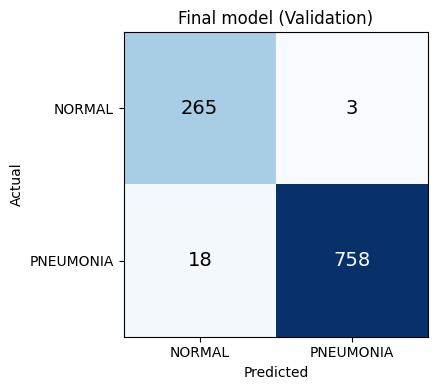

In [6]:
# 6. Validation result & confusion matrix


import matplotlib.pyplot as plt

v = evaluate(model, val_loader)
print(f"Accuracy {v['acc']:.4f} | AUC {v['auc']:.4f} | Sensitivity {v['sens']:.4f} | "
      f"Specificity {v['spec']:.4f} | F1 {v['f1']:.4f} | FN {v['fn']} | FP {v['fp']}")
print("expected (E1b): Acc 0.9799 | AUC 0.9979 | Sens 0.9768 | Spec 0.9888 | FN 18 | FP 3")

cm = np.array([[v["tn"], v["fp"]], [v["fn"], v["tp"]]])
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["NORMAL", "PNEUMONIA"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["NORMAL", "PNEUMONIA"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Final model (Validation)")
plt.tight_layout(); plt.show()


# → 최종 모델의 검증 지표와 혼동행렬을 보고, 실험 E1b 기록과 같은 값인지(재현성) 확인하겠다

In [7]:
# 7. Test prediction & submission


@torch.no_grad()
def predict(model, loader):
    model.eval()
    return np.array([p for x in loader for p in torch.softmax(model(x.to(device)), dim=1)[:, 1].cpu().numpy()])

test_probs = predict(model, test_loader)
test_preds = (test_probs >= 0.5).astype(int)   # competition metric = Accuracy → 0/1 at 0.5

sub = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
assert (sub["file_name"].values == test_df["file_name"].values).all()
sub["label"] = test_preds
sub.to_csv(os.path.join(OUT_DIR, "final_submission.csv"), index=False)
print("test normal ratio:", round(1 - test_preds.mean(), 3), "| test prob median:", round(float(np.median(test_probs)), 3))

# Reproducibility check against the submitted E1b file (leaderboard 0.9407)
e1b_path = os.path.join(PROJECT_DIR, "submissions", "E1b.csv")
if os.path.exists(e1b_path):
    n_diff = int((pd.read_csv(e1b_path)["label"].values != test_preds).sum())
    print("different predictions vs submitted E1b.csv:", n_diff, "/ 624")


# → 테스트 624장을 예측해 제출 파일을 만들고, 리더보드 0.9407을 받은 E1b.csv와 예측이 완전히 같은지 확인하겠다

test normal ratio: 0.386 | test prob median: 0.982
different predictions vs submitted E1b.csv: 0 / 624


In [8]:
# 8. Grad-CAM (layer4)


import torch.nn.functional as F

class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._hook)
    def _hook(self, m, i, out):
        self.acts = out.detach()
        out.register_hook(lambda g: setattr(self, "grads", g.detach()))
    def __call__(self, x):
        self.model.zero_grad()
        out = self.model(x)
        cls = out.argmax(1)
        out.gather(1, cls.view(-1, 1)).sum().backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)            # channel importance
        cam = F.relu((w * self.acts).sum(dim=1, keepdim=True))    # weighted sum of feature maps
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        cam = (cam - cam.amin((1, 2), keepdim=True)) / (cam.amax((1, 2), keepdim=True) - cam.amin((1, 2), keepdim=True) + 1e-8)
        return cam.cpu().numpy(), torch.softmax(out, 1)[:, 1].detach().cpu().numpy()

cam_engine = GradCAM(model, model.layer4)
model.eval()

def gray(x):
    return np.clip(x[0, 0].cpu().numpy() * IMAGENET_STD[0] + IMAGENET_MEAN[0], 0, 1)

samples = (val_df[val_df["label"] == 1]["file_name"].head(3).tolist()
           + val_df[val_df["label"] == 0]["file_name"].head(3).tolist())
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for j, f in enumerate(samples):
    x = tf(Image.open(os.path.join(TRAIN_IMG_DIR, f)).convert("L")).unsqueeze(0).to(device)
    cam, p = cam_engine(x)
    label = int(val_df.loc[val_df["file_name"] == f, "label"].values[0])
    axes[0, j].imshow(gray(x), cmap="gray"); axes[0, j].axis("off")
    axes[0, j].set_title(f"{'PNEU' if label else 'NORMAL'} p={p[0]:.2f}", fontsize=9)
    axes[1, j].imshow(gray(x), cmap="gray"); axes[1, j].imshow(cam[0], cmap="Reds", alpha=0.5); axes[1, j].axis("off")
plt.suptitle("Grad-CAM : final model (validation samples)"); plt.tight_layout(); plt.show()


# → 최종 모델의 마지막 합성곱 층에서 Grad-CAM을 계산해, 폐렴·정상 샘플에서 어디를 보고 판단했는지 보여주겠다

[X-ray 이미지 출력 제거 — 대회 데이터 재배포 금지. 해석은 04_Report/Final_Report.md 참고]


In [9]:
# 9. Result records (prob · label · risk level)


LOW_T, HIGH_T = 0.1, 0.9   # chosen on validation only (sensitivity first)

def risk_level(p):
    return "Low" if p < LOW_T else ("High" if p >= HIGH_T else "Medium")

records = pd.DataFrame({
    "file_name": test_df["file_name"],
    "image_path": [os.path.join(TEST_IMG_DIR, f) for f in test_df["file_name"]],   # original image
    "prob_pneumonia": np.round(test_probs, 4),                                       # softmax[:, 1] in predict()
    "pred_label": test_preds,                                                        # prob >= 0.5
    "risk_level": [risk_level(p) for p in test_probs],                               # Low / Medium / High
    "model_version": "resnet18_full_ft_E1b",
})
records.to_csv(os.path.join(OUT_DIR, "result_records.csv"), index=False)
display(records.head())
print(records["risk_level"].value_counts())


# → 테스트 이미지마다 원본 경로·폐렴 확률·판정·위험도·모델 버전을 한 줄로 정리해 결과 데이터로 저장하겠다

,file_name,image_path,prob_pneumonia,pred_label,risk_level,model_version
0,test_0001.png,/content/data/test/test_0001.png,0.0000,0,Low,resnet18_full_ft_E1b
1,test_0002.png,/content/data/test/test_0002.png,0.0132,0,Low,resnet18_full_ft_E1b
2,test_0003.png,/content/data/test/test_0003.png,0.9149,1,High,resnet18_full_ft_E1b
3,test_0004.png,/content/data/test/test_0004.png,0.9982,1,High,resnet18_full_ft_E1b
4,test_0005.png,/content/data/test/test_0005.png,0.9919,1,High,resnet18_full_ft_E1b


risk_level
High      355
Low       213
Medium     56
Name: count, dtype: int64


## Summary

| 실험 | 변경 | Val AUC | 리더보드 | 판단 |
|---|---|---|---|---|
| E0 | Baseline SimpleCNN 128, 2ep | 0.9832 | 0.7468 | 기준 |
| E1a | ResNet18, 분류층만 학습 | 0.9944 | 0.8333 | 미채택 |
| **E1b** | **ResNet18, 전체 미세조정** | **0.9979** | **0.9407** | **최종** |
| E2 | + 검은 여백 Crop | 0.9988 | 0.9022 | 미채택 (가로세로 비율 지름길) |
| E2b | + Crop + 고정 비율 1.3 | 0.9967 | 0.8990 | 미채택 |
| E4 | + 클래스 가중치 손실 | 0.9984 | 0.9327 | 미채택 (FN 증가) |
| E5 | + 코사인 학습률 스케줄러 | 0.9983 | 0.9375 | 미채택 (테스트 정상 예측 비율 하락) |

- 검증 점수가 더 높은 실험(E2·E4·E5)이 리더보드에서는 모두 E1b보다 낮았음 → 학습(224 가공본)과 테스트(원본 크기) 분포 차이 때문에 **검증셋이 테스트를 대변하지 못함**
- **테스트 정상 예측 비율**(실제 약 0.375)이 리더보드 방향을 미리 알려준 간접 지표로 작동